In [1]:
#Imports the libraries used for the classification models and evaluation.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from torch.utils.data import TensorDataset, DataLoader

In [2]:
#Sets the training parameters and selected device.
batch_size = 32
learning_rate = 0.001
N_Epochs = 100
epsilon = 0.0001

np.random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


In [3]:
#Reads the phishing website dataset from a local CSV file.
path_data = 'phishing_websites.csv'
PHISH_raw_data = pd.read_csv(path_data)
print(PHISH_raw_data.shape)
print(PHISH_raw_data.columns.tolist())
PHISH_raw_data.head()

(11055, 32)
['index', 'having_IPhaving_IP_Address', 'URLURL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']


,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [4]:
#Cleans the dataset and converts website labels into 0 and 1.
data = PHISH_raw_data.copy()
data.columns = data.columns.str.strip()
data = data.loc[:, ~data.columns.str.lower().str.startswith('unnamed:')]
data = data.drop(columns=[c for c in data.columns if c.lower() in ('id', 'index')])

label_columns = [c for c in data.columns if c.lower() in ('result', 'class', 'label', 'status')]
if len(label_columns) != 1:
    raise ValueError('Check the label column name: ' + str(data.columns.tolist()))
label_column = label_columns[0]

labels = data[label_column].astype(str).str.strip().str.lower()
if set(labels.unique()) <= {'-1', '1'}:
    y = (labels == '-1').astype(int).to_numpy()
elif set(labels.unique()) <= {'0', '1'}:
    y = labels.astype(int).to_numpy()
elif set(labels.unique()) <= {'phishing', 'legitimate', 'benign'}:
    y = labels.map({'phishing': 1, 'legitimate': 0, 'benign': 0}).to_numpy(dtype=int)
else:
    raise ValueError('Unknown class values: ' + str(labels.unique()))

X_data = data.drop(columns=[label_column]).apply(pd.to_numeric, errors='coerce')
if X_data.isna().any().any():
    raise ValueError('Missing or nonnumeric features: ' + str(X_data.columns[X_data.isna().any()].tolist()))

feature_columns = X_data.columns.tolist()
X = X_data.to_numpy(dtype=np.float32)
y = y.astype(np.int64)
print('Feature count:', X.shape[1])
print('Class counts (0=Legitimate, 1=Phishing):', np.bincount(y))

Feature count: 30
Class counts (0=Legitimate, 1=Phishing): [6157 4898]


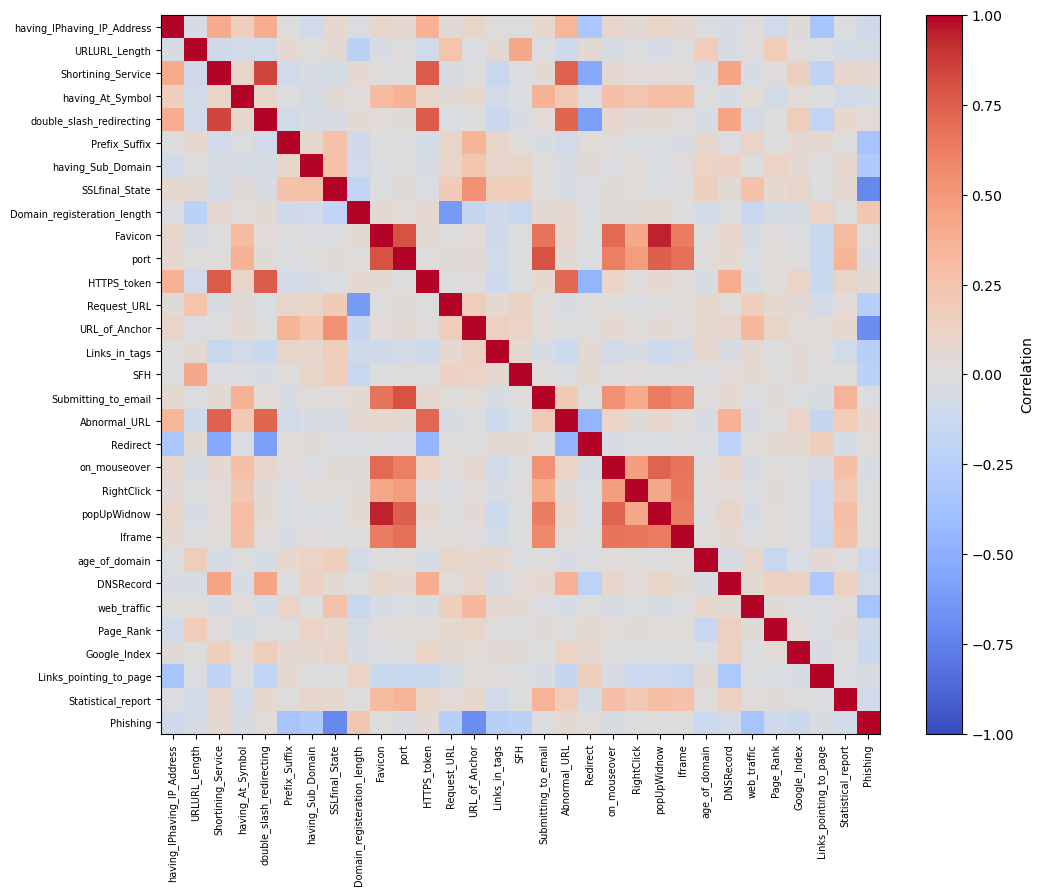

In [5]:
#Displays the correlation matrix for the website features and label.
corr_data = X_data.copy()
corr_data['Phishing'] = y
correlation = corr_data.corr(numeric_only=True)
plt.figure(figsize=(11, 9))
plt.imshow(correlation, vmin=-1, vmax=1, cmap='coolwarm')
plt.xticks(range(len(correlation)), correlation.columns, rotation=90, fontsize=7)
plt.yticks(range(len(correlation)), correlation.columns, fontsize=7)
plt.colorbar(label='Correlation')
plt.tight_layout()
plt.show()

In [6]:
#Splits the data into training, validation, and testing sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.20, random_state=42, stratify=y_train)
x_means = torch.tensor(X_train.mean(axis=0, keepdims=True))
x_deviations = torch.tensor(X_train.std(axis=0, keepdims=True) + epsilon)
train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
print('Training:', len(X_train), 'Validation:', len(X_val), 'Testing:', len(X_test))

Training: 7075 Validation: 1769 Testing: 2211


In [7]:
#Defines the linear classification model used as the baseline.
class LinNet(nn.Module):
    def __init__(self, n_features, means, deviations):
        super().__init__()
        self.register_buffer('means', means)
        self.register_buffer('deviations', deviations)
        self.linear1 = nn.Linear(n_features, 2)

    def forward(self, x):
        x = (x - self.means) / self.deviations
        return self.linear1(x)

In [8]:
#Defines the one-hidden-layer MLP classification model.
class MLP_Net(nn.Module):
    def __init__(self, n_features, means, deviations):
        super().__init__()
        self.register_buffer('means', means)
        self.register_buffer('deviations', deviations)
        self.linear1 = nn.Linear(n_features, 32)
        self.act1 = nn.ReLU()
        self.linear2 = nn.Linear(32, 2)

    def forward(self, x):
        x = (x - self.means) / self.deviations
        x = self.act1(self.linear1(x))
        return self.linear2(x)

In [9]:
#Defines the deep classification model using two hidden layers.
class DL_Net(nn.Module):
    def __init__(self, n_features, means, deviations):
        super().__init__()
        self.register_buffer('means', means)
        self.register_buffer('deviations', deviations)
        self.linear1 = nn.Linear(n_features, 64)
        self.act1 = nn.ReLU()
        self.linear2 = nn.Linear(64, 32)
        self.act2 = nn.ReLU()
        self.linear3 = nn.Linear(32, 2)

    def forward(self, x):
        x = (x - self.means) / self.deviations
        x = self.act1(self.linear1(x))
        x = self.act2(self.linear2(x))
        return self.linear3(x)

In [10]:
#Trains a PyTorch classifier using cross-entropy loss and Adam.
def training_loop(N_Epochs, model, loss_fn, opt):
    history = []
    for epoch in range(N_Epochs):
        model.train()
        losses = []
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            y_pred = model(xb)
            loss = loss_fn(y_pred, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            losses.append(loss.item())
        history.append(np.mean(losses))
        if epoch % 20 == 0 or epoch == N_Epochs - 1:
            print(epoch, 'loss=', round(history[-1], 4))
    return history

#Calculates accuracy, precision, recall, and F1 score.
def print_metrics_function(y_real, y_pred):
    print('Accuracy:', round(accuracy_score(y_real, y_pred), 4))
    print('Precision:', round(precision_score(y_real, y_pred, zero_division=0), 4))
    print('Recall:', round(recall_score(y_real, y_pred, zero_division=0), 4))
    print('F1-measure:', round(f1_score(y_real, y_pred, zero_division=0), 4))

In [11]:
#Trains and compares the linear, MLP, and deep MLP models.
n_features = X_train.shape[1]
models = {
    'Linear': LinNet(n_features, x_means, x_deviations),
    'MLP': MLP_Net(n_features, x_means, x_deviations),
    'Deep MLP': DL_Net(n_features, x_means, x_deviations)
}

results = []
histories = {}
for name, model in models.items():
    print('\nTraining:', name)
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=learning_rate)
    histories[name] = training_loop(N_Epochs, model, nn.CrossEntropyLoss(), opt)
    model.eval()
    with torch.no_grad():
        y_pred = model(torch.tensor(X_val).to(device)).argmax(dim=1).cpu().numpy()
    results.append([name, accuracy_score(y_val, y_pred), precision_score(y_val, y_pred, zero_division=0),
                    recall_score(y_val, y_pred, zero_division=0), f1_score(y_val, y_pred, zero_division=0)])

results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1'])
results_df = results_df.sort_values('F1', ascending=False).reset_index(drop=True)
results_df.round(4)


Training: Linear
0 loss= 0.5778
20 loss= 0.1811
40 loss= 0.1782
60 loss= 0.1818
80 loss= 0.178
99 loss= 0.1776

Training: MLP
0 loss= 0.3686
20 loss= 0.0905
40 loss= 0.0693
60 loss= 0.0563
80 loss= 0.0492
99 loss= 0.0452

Training: Deep MLP
0 loss= 0.2768
20 loss= 0.0556
40 loss= 0.0392
60 loss= 0.0359
80 loss= 0.0338
99 loss= 0.0299


,Model,Accuracy,Precision,Recall,F1
0,Deep MLP,0.9627,0.9556,0.9605,0.9580
1,MLP,0.9548,0.9400,0.9592,0.9495
2,Linear,0.9322,0.9334,0.9120,0.9226


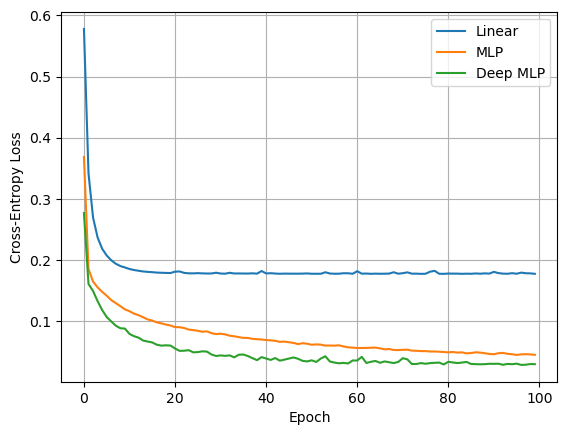

In [12]:
#Plots the training loss for all three models.
for name, values in histories.items():
    plt.plot(values, label=name)
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.legend()
plt.grid(True)
plt.show()

Best model: Deep MLP
Accuracy: 0.9697
Precision: 0.9731
Recall: 0.9582
F1-measure: 0.9656
Confusion matrix (0=Legitimate, 1=Phishing):
[[1205   26]
 [  41  939]]
              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.97      1231
    Phishing       0.97      0.96      0.97       980

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211



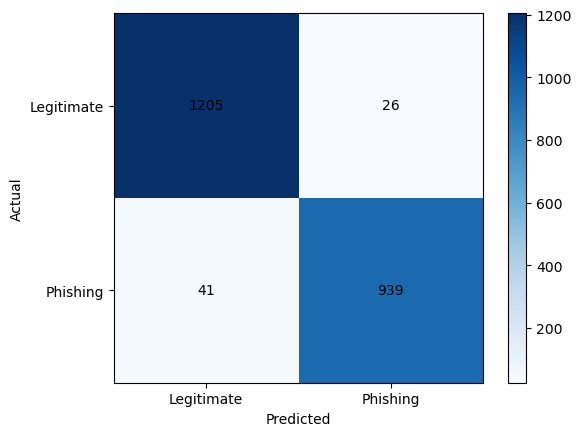

In [13]:
#Tests the model with the best validation F1 score.
best_name = results_df.iloc[0]['Model']
best_model = models[best_name]
best_model.eval()
with torch.no_grad():
    y_pred = best_model(torch.tensor(X_test).to(device)).argmax(dim=1).cpu().numpy()

print('Best model:', best_name)
print_metrics_function(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print('Confusion matrix (0=Legitimate, 1=Phishing):')
print(cm)
print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Phishing'], zero_division=0))
plt.imshow(cm, cmap='Blues')
plt.xticks([0, 1], ['Legitimate', 'Phishing'])
plt.yticks([0, 1], ['Legitimate', 'Phishing'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.colorbar()
plt.show()

In [14]:
#Exports the best classifier as one ONNX file for GitHub Pages.
best_model = best_model.cpu().eval()
torch.onnx.export(
    best_model,
    torch.zeros(1, n_features, dtype=torch.float32),
    'phishing_model.onnx',
    input_names=['input'],
    output_names=['logits'],
    opset_version=17,
    external_data=False
)
print('Saved phishing_model.onnx')
print('Feature order for the website:', feature_columns)
print('ONNX output: [Legitimate, Phishing] logits')

W1116 12:32:32.056000 2484 site-packages\torch\onnx\_internal\exporter\_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W1116 12:32:32.889000 2484 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1116 12:32:32.892000 2484 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1116 12:32:32.894000 2484 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1116 12:32:32.8960

[torch.onnx] Obtain model graph for `DL_Net([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DL_Net([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Saved phishing_model.onnx
Feature order for the website: ['having_IPhaving_IP_Address', 'URLURL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report']
ONNX output: [Legitimate, Phishing] logits
